# 第 49 课｜statsmodels 因子回归与稳健推断

本 Notebook 对应「365 天量化金融」第 49 课。课程方法来自本地完整视频、课件截图和本地 Whisper 口播整理；这里把它重建为默认离线、可核对、可重复执行的量化教学实现。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/49_youtube-II9gdYytXMk/index.html`
- 环境：`pkm-quant`
- 数据：固定随机种子的模拟因子与资产收益
- 状态：可运行学习稿；不代表策略收益承诺

> 网络接口和研究计算分离：Notebook 默认不请求第三方服务。真实接口只作为适配层示意，计算使用带来源声明的本地快照，避免限流、字段变化和历史数据重算破坏复现。

## 本节量化问题

因子回归把资产超额收益拆成 Alpha、市场/风格暴露和残差。本节不仅输出系数，还同时输出标准误、t 值、p 值、置信区间、R² 和滚动稳定性。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


In [2]:
# statsmodels 的公式接口负责 OLS；HAC 用于时间序列稳健标准误。
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels
print("statsmodels:", statsmodels.__version__)

statsmodels: 0.14.6


## 1. 构造已知真值的三因子样本

模型为：

`asset_excess = alpha + beta_m*MKT + beta_s*SMB + beta_h*HML + epsilon`

因为真实参数由我们设置，回归结果可以与真值核对；这比拿未知真实数据只看 p 值更适合学习。

In [3]:
# 生成 756 日因子和带自相关噪声的模拟资产超额收益。
rng = np.random.default_rng(365)
n = 756
dates = pd.bdate_range("2023-01-03", periods=n)
factors = pd.DataFrame({
    "MKT": rng.normal(0.0003, 0.010, n),
    "SMB": rng.normal(0.0000, 0.006, n),
    "HML": rng.normal(0.0000, 0.005, n),
}, index=dates)
epsilon = np.zeros(n)
innovations = rng.normal(0, 0.007, n)
for i in range(1, n):
    epsilon[i] = 0.25 * epsilon[i - 1] + innovations[i]
true_params = {"Intercept": 0.00015, "MKT": 1.10, "SMB": 0.35, "HML": -0.20}
factors["asset_excess"] = (
    true_params["Intercept"] + 1.10 * factors["MKT"]
    + 0.35 * factors["SMB"] - 0.20 * factors["HML"] + epsilon
)
display(factors.head())

,MKT,SMB,HML,asset_excess
2023-01-03,-0.001064,-0.013290,-0.007441,-0.004184
2023-01-04,0.001241,0.002679,-0.009436,-0.004711
2023-01-05,-0.000330,-0.001844,0.004768,-0.008930
2023-01-06,0.010839,-0.004105,0.011226,0.005448
2023-01-09,-0.006567,-0.009722,-0.000106,-0.012918


## 2. OLS 系数与 HAC/Newey–West 标准误

HAC 不改变 OLS 系数点估计，只调整标准误和推断。`maxlags=5` 是本例的日频演示参数，不是通用最优值。

In [4]:
# 拟合三因子回归，并用 HAC 协方差重新计算推断。
ols = smf.ols("asset_excess ~ MKT + SMB + HML", data=factors).fit()
hac = ols.get_robustcov_results(cov_type="HAC", maxlags=5)
names = ols.model.exog_names
result = pd.DataFrame({
    "estimate": hac.params,
    "std_error_HAC": hac.bse,
    "t_value": hac.tvalues,
    "p_value": hac.pvalues,
}, index=names)
confidence = pd.DataFrame(hac.conf_int(), index=names, columns=["ci_low", "ci_high"])
result = result.join(confidence)
result["true_value"] = pd.Series(true_params)

display(result)
print("R²:", round(ols.rsquared, 4))
print("日 Alpha 简单年化:", f"{result.loc['Intercept', 'estimate'] * 252:.2%}")
assert abs(result.loc["MKT", "estimate"] - 1.10) < 0.15

,estimate,std_error_HAC,t_value,p_value,ci_low,ci_high,true_value
Intercept,-0.000063,0.000338,-0.186672,8.519685e-01,-0.000726,0.000600,0.00015
MKT,1.113646,0.026306,42.334264,3.242032e-201,1.062004,1.165288,1.10000
SMB,0.362393,0.040579,8.930471,3.217362e-18,0.282731,0.442055,0.35000
HML,-0.180849,0.047000,-3.847888,1.292540e-04,-0.273115,-0.088583,-0.20000


R²: 0.7044
日 Alpha 简单年化: -1.59%


## 3. Alpha、Beta、R² 回答不同问题

- Alpha：控制因子后的截距；
- Beta：条件平均敏感度；
- R²：样本内收益变异的解释比例。

R² 高不代表收益高，Alpha 显著也不自动代表可交易超额。

In [5]:
# 用一张解释表防止混用三个指标。
interpretation = pd.DataFrame([
    {"指标": "Alpha", "本例数值": result.loc["Intercept", "estimate"], "回答": "控制因子后的平均截距"},
    {"指标": "Market Beta", "本例数值": result.loc["MKT", "estimate"], "回答": "市场变化 1 单位时的条件变化"},
    {"指标": "R²", "本例数值": ols.rsquared, "回答": "样本内被模型解释的变异比例"},
])
display(interpretation)

,指标,本例数值,回答
0,Alpha,-0.000063,控制因子后的平均截距
1,Market Beta,1.113646,市场变化 1 单位时的条件变化
2,R²,0.704370,样本内被模型解释的变异比例


## 4. 滚动回归检查暴露是否稳定

固定窗口只使用窗口内样本。下面每 20 日估计一次最近 126 日市场 Beta；这是诊断区间稳定性，不是预测未来 Beta。

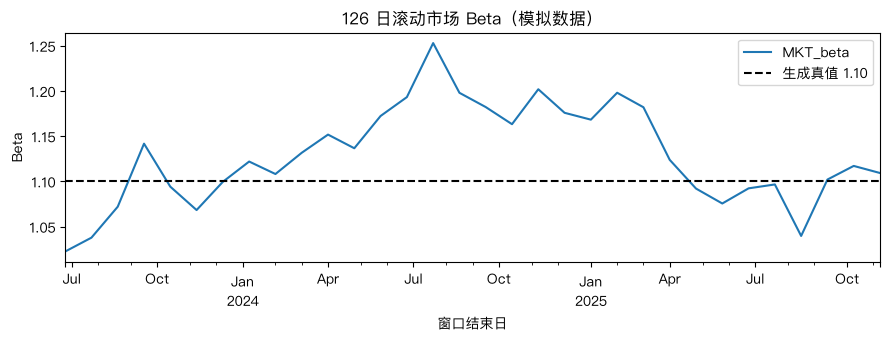

In [6]:
# 用 126 日窗口滚动估计市场 Beta，减少图中重复点。
rolling_rows = []
window = 126
for end in range(window, len(factors) + 1, 20):
    sample = factors.iloc[end - window:end]
    fit = smf.ols("asset_excess ~ MKT + SMB + HML", data=sample).fit()
    rolling_rows.append({"date": sample.index[-1], "MKT_beta": fit.params["MKT"]})
rolling_beta = pd.DataFrame(rolling_rows).set_index("date")
axis = rolling_beta.plot(figsize=(9, 3.5), title="126 日滚动市场 Beta（模拟数据）")
axis.axhline(1.10, color="black", linestyle="--", label="生成真值 1.10")
axis.set(xlabel="窗口结束日", ylabel="Beta")
axis.legend()
axis.figure.tight_layout()
axis.figure.savefig(OUTPUT_DIR / "49_rolling_beta.png", dpi=150)
plt.show()
assert len(rolling_beta) > 20

## 方法边界与复用结论


- 金融误差常有异方差和自相关，时间序列推断应考虑 HAC 或更完整模型。
- 因子暴露会漂移，整段回归只是区间平均。
- 显著 Alpha 仍可能来自遗漏因子、数据挖掘、成本或不可交易暴露。


本课代码验证的是方法和数据契约，不是未来收益。迁移到真实研究前，还需重新核对来源授权、复权、时区、可得时间、交易成本和样本外边界。